# Diagn?stico do Cancro da Mama: EDA, CNN, XAI e Active Learning

# 01 - Análise Exploratória de Dados (EDA) e Pré-processamento

**Projeto:** Diagnóstico de Cancro da Mama com CNNs e Active Learning
**Unidade Curricular:** Inteligência Artificial Centrada no Humano

Neste notebook, vamos:
1. Carregar as imagens de ultrassom **e as respetivas máscaras de lesão**.
2. Analisar a distribuição das classes (EDA).
3. Fazer a divisão correta dos dados em Treino, Validação e Teste (estratificada).
4. Guardar os dados processados em ficheiros `.npz` para acelerar o treino no próximo notebook.

**Novidade:** as máscaras de lesão são guardadas juntamente com as imagens, para permitir a **avaliação objetiva do Grad-CAM** (IoU/Dice) no notebook 03.



## 1. Setup e Montagem do Drive

Vamos montar o Google Drive para aceder às imagens originais e importar as bibliotecas necessárias.


In [ ]:
from google.colab import drive
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
import time
import json

# Montar o Drive
drive.mount('/content/drive')

PATH = "/content/drive/MyDrive/Projeto/data/img"
ficheiros = os.listdir(PATH)

print(f"Total de ficheiros encontrados na pasta: {len(ficheiros)}")

print("\nPrimeiros 15 ficheiros (para ver o padrão de nomes):")
for f in ficheiros[:15]:
    print(" -", f)

# Diagnóstico de máscaras
masks_encontradas = [f for f in ficheiros if "mask" in f.lower()]
print(f"\nFicheiros que contêm 'mask' no nome: {len(masks_encontradas)}")

if len(masks_encontradas) == 0:
    print("→ O dataset fornecido NÃO inclui máscaras de lesão.")
    print("→ O Grad-CAM (Notebook 03) será avaliado QUALITATIVAMENTE (visual),")
    print("   conforme previsto na secção 7 da proposta.")
else:
    print("→ Máscaras encontradas. IoU/Dice poderão ser calculados no Notebook 03.")

Mounted at /content/drive
Total de ficheiros encontrados na pasta: 780

Primeiros 15 ficheiros (para ver o padrão de nomes):
 - normal (27).png
 - normal (109).png
 - normal (61).png
 - normal (83).png
 - normal (123).png
 - normal (56).png
 - normal (36).png
 - normal (95).png
 - normal (31).png
 - normal (70).png
 - normal (16).png
 - normal (14).png
 - normal (129).png
 - normal (107).png
 - normal (119).png

Ficheiros que contêm 'mask' no nome: 0
→ O dataset fornecido NÃO inclui máscaras de lesão.
→ O Grad-CAM (Notebook 03) será avaliado QUALITATIVAMENTE (visual),
   conforme previsto na secção 7 da proposta.


## 2. Verificação de Máscaras

Antes de carregar tudo, confirmamos que as máscaras estão disponíveis. Para cada imagem `nome.png` deve existir `nome_mask.png`.

- **Imagens originais**: todas as que **não** acabam em `_mask.png`.
- **Máscaras**: todas as que acabam em `_mask.png`.

In [ ]:
imagens_ficheiros = [f for f in ficheiros if not f.endswith("_mask.png")]
mask_ficheiros    = [f for f in ficheiros if f.endswith("_mask.png")]

print(f"Imagens originais: {len(imagens_ficheiros)}")
print(f"Máscaras:          {len(mask_ficheiros)}")

if len(mask_ficheiros) == 0:
    print("\n ATENÇÃO: não foram encontradas máscaras na pasta.")
    print("   → O modelo treina normalmente.")
    print("   → A avaliação quantitativa do Grad-CAM (IoU/Dice) NÃO será feita.")
    print("   → A avaliação do XAI será QUALITATIVA (inspeção visual do alinhamento")
    print("     entre heatmaps e regiões de interesse clínico — secção 7 da proposta).")
elif len(imagens_ficheiros) == len(mask_ficheiros):
    print("\n Cada imagem tem a sua máscara correspondente.")
else:
    print(f"\n Há {len(imagens_ficheiros) - len(mask_ficheiros)} imagens sem máscara.")
    print("   O código usa máscara vazia como fallback.")

# Mostrar um exemplo
if len(imagens_ficheiros) > 0 and len(mask_ficheiros) > 0:
    print(f"\nExemplo de imagem:  {imagens_ficheiros[0]}")
    print(f"Exemplo de máscara: {mask_ficheiros[0]}")

Imagens originais: 780
Máscaras:          0

 ATENÇÃO: não foram encontradas máscaras na pasta.
   → O modelo treina normalmente.
   → A avaliação quantitativa do Grad-CAM (IoU/Dice) NÃO será feita.
   → A avaliação do XAI será QUALITATIVA (inspeção visual do alinhamento
     entre heatmaps e regiões de interesse clínico — secção 7 da proposta).


## 3. Análise Exploratória de Dados (EDA)

Vamos verificar o balanceamento do dataset original para entender se será necessário aplicar técnicas de balanceamento (como `class_weight`) no treino.

/tmp/ipykernel_549/279556531.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=classes, y=counts, palette="Blues")


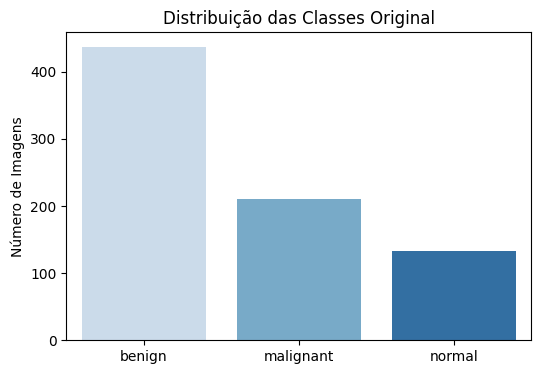

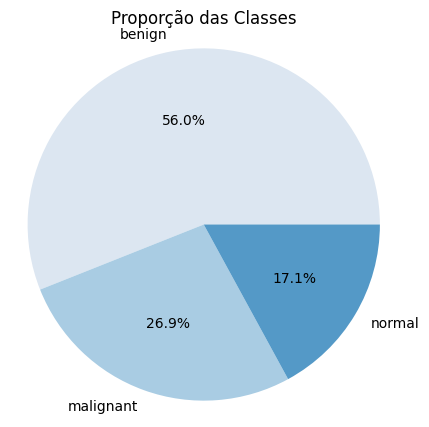

Contagens por classe:
  benign      : 437 imagens
  malignant   : 210 imagens
  normal      : 133 imagens


In [ ]:
# Extrair as labels dos nomes das imagens (ignorar as máscaras)
labels0 = [name.split(" ")[0] for name in imagens_ficheiros]
classes, counts = np.unique(labels0, return_counts=True)

# Gráfico de barras
plt.figure(figsize=(6, 4))
sns.barplot(x=classes, y=counts, palette="Blues")
plt.title("Distribuição das Classes Original")
plt.ylabel("Número de Imagens")
plt.show()

# Gráfico de pizza
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=classes, autopct='%1.1f%%', colors=['#dce6f1', '#a9cce3', '#5499c7'])
plt.title('Proporção das Classes')
plt.axis('equal')
plt.show()

print("Contagens por classe:")
for c, n in zip(classes, counts):
    print(f"  {c:<12}: {n} imagens")

## 4. Carregamento e Divisão dos Dados

**Importante:** Para evitar *Data Leakage*, a divisão dos dados em treino, validação e teste é feita **antes** de qualquer transformação (data augmentation). O data augmentation será aplicado apenas no conjunto de treino, em tempo real, no próximo notebook.

4.1 **As máscaras seguem a mesma divisão das imagens** (via `train_test_split` com os mesmos índices), para garantir que cada imagem de teste tem a sua máscara correspondente.

In [ ]:
print("A carregar as imagens (e máscaras, se existirem)...")
inicio = time.time()

IMG_SIZE = 224
images = []
masks  = []
labels = []
label_map = {"benign": 0, "malignant": 1, "normal": 2}

todas_as_masks = {f: f for f in os.listdir(PATH) if "mask" in f.lower()}

n_masks_encontradas = 0
n_masks_vazias = 0

for name in imagens_ficheiros:
    # 1. Carregar imagem
    img = Image.open(os.path.join(PATH, name)).convert('L').resize((IMG_SIZE, IMG_SIZE))
    images.append(np.asarray(img, dtype=np.float32) / np.float32(255.0))
    labels.append(label_map[name.split(" ")[0]])

    # 2. Procurar a máscara correspondente
    mask_name = name.replace(".png", "_mask.png")
    mask_path = os.path.join(PATH, mask_name)

    if not os.path.exists(mask_path):
        base_name = os.path.splitext(name)[0]
        for m_file in todas_as_masks:
            if base_name in m_file:
                mask_path = os.path.join(PATH, m_file)
                break

    if os.path.exists(mask_path):
      # Para máscaras, usar vizinho mais próximo para preservar as regiões anotadas
      m = Image.open(mask_path).convert("L").resize(
          (IMG_SIZE, IMG_SIZE),
          resample=Image.Resampling.NEAREST)

      # Converte a máscara para valores 0 ou 1
      mask_array = np.asarray(m, dtype=np.uint8)
      masks.append((mask_array >= 128).astype(np.float32))
      n_masks_encontradas += 1
    else:
      # Máscara vazia de substituição; não é uma anotação real
      masks.append(np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32))
      n_masks_vazias += 1

# Flag global para o Notebook 03 saber o que fazer
tem_mascaras_reais = (n_masks_encontradas > 0)

images = np.asarray(images, dtype=np.float32)[..., np.newaxis]
masks  = np.asarray(masks, dtype=np.float32)[..., np.newaxis]
labels = np.asarray(labels, dtype=np.int64)

print(f"\n Carregamento concluído em {time.time()-inicio:.1f}s")
print(f"Shape imagens:   {images.shape}")
print(f"Shape máscaras:  {masks.shape}")
print(f"Máscaras encontradas: {n_masks_encontradas}/{len(imagens_ficheiros)}")
print(f"Máscaras vazias (fallback): {n_masks_vazias}")
print(f"\n→ tem_mascaras_reais = {tem_mascaras_reais}")
if not tem_mascaras_reais:
    print("   (NB03 fará avaliação qualitativa do Grad-CAM)")

# --- Divisão ---
# --- Divisão estratificada: 70% treino, 15% validação, 15% teste ---
# Guardamos os índices para verificar que não há sobreposição entre conjuntos.

indices = np.arange(len(labels))

idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    stratify=labels[idx_temp],
    random_state=42
)

# Criar os conjuntos usando os mesmos índices para imagens, máscaras e labels
x_train, y_train, m_train = images[idx_train], labels[idx_train], masks[idx_train]
x_val,   y_val,   m_val   = images[idx_val],   labels[idx_val],   masks[idx_val]
x_test,  y_test,  m_test  = images[idx_test],  labels[idx_test],  masks[idx_test]

# Confirmar que nenhum índice aparece em mais do que um conjunto
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

print(f"Treino:    {len(idx_train)} imagens")
print(f"Validação: {len(idx_val)} imagens")
print(f"Teste:     {len(idx_test)} imagens")

A carregar as imagens (e máscaras, se existirem)...

 Carregamento concluído em 25.5s
Shape imagens:   (780, 224, 224, 1)
Shape máscaras:  (780, 224, 224, 1)
Máscaras encontradas: 0/780
Máscaras vazias (fallback): 780

→ tem_mascaras_reais = False
   (NB03 fará avaliação qualitativa do Grad-CAM)
Treino:    546 imagens
Validação: 117 imagens
Teste:     117 imagens


### 4.2 Verificação da distribuição e dos dados divididos

Depois de separar as imagens em conjuntos de treino, validação e teste, verificamos quantas imagens de cada classe existem em cada conjunto. Como a divisão foi estratificada, espera-se que as proporções das classes sejam semelhantes, embora possam existir pequenas diferenças devido ao arredondamento.

Verificamos também as dimensões e os tipos de dados das imagens, máscaras e etiquetas. Estas verificações ajudam a detetar problemas na preparação dos dados antes do treino.

O número de máscaras reais encontradas indica se existem máscaras de lesão disponíveis. Máscaras vazias criadas para substituir ficheiros ausentes não são anotações reais e não devem ser usadas para avaliar quantitativamente o Grad-CAM.

In [ ]:
classes_nomes = {
    0: "benign",
    1: "malignant",
    2: "normal"
}

for nome, indices_split in [
    ("Treino", idx_train),
    ("Validação", idx_val),
    ("Teste", idx_test)
]:
    contagens = np.bincount(labels[indices_split], minlength=3)
    total = len(indices_split)

    print(f"\n{nome} — {total} imagens")
    for classe_id, classe_nome in classes_nomes.items():
        percentagem = 100 * contagens[classe_id] / total
        print(
            f"  {classe_nome:10s}: "
            f"{contagens[classe_id]:3d} ({percentagem:5.1f}%)"
        )

print("\nTipos e dimensões:")
print(f"Imagens de treino: {x_train.shape} | {x_train.dtype}")
print(f"Máscaras de treino: {m_train.shape} | {m_train.dtype}")
print(f"Labels de treino: {y_train.shape} | {y_train.dtype}")
print(f"Máscaras reais encontradas: {n_masks_encontradas}")


Treino — 546 imagens
  benign    : 306 ( 56.0%)
  malignant : 147 ( 26.9%)
  normal    :  93 ( 17.0%)

Validação — 117 imagens
  benign    :  65 ( 55.6%)
  malignant :  32 ( 27.4%)
  normal    :  20 ( 17.1%)

Teste — 117 imagens
  benign    :  66 ( 56.4%)
  malignant :  31 ( 26.5%)
  normal    :  20 ( 17.1%)

Tipos e dimensões:
Imagens de treino: (546, 224, 224, 1) | float32
Máscaras de treino: (546, 224, 224, 1) | float32
Labels de treino: (546,) | int64
Máscaras reais encontradas: 0


## 5. Visualização de Amostras (Imagem + Máscara)

Antes de guardar, confirmamos visualmente que as máscaras estão bem alinhadas com as imagens (uma máscara de lesão deve estar "por cima" da lesão visível na ecografia).

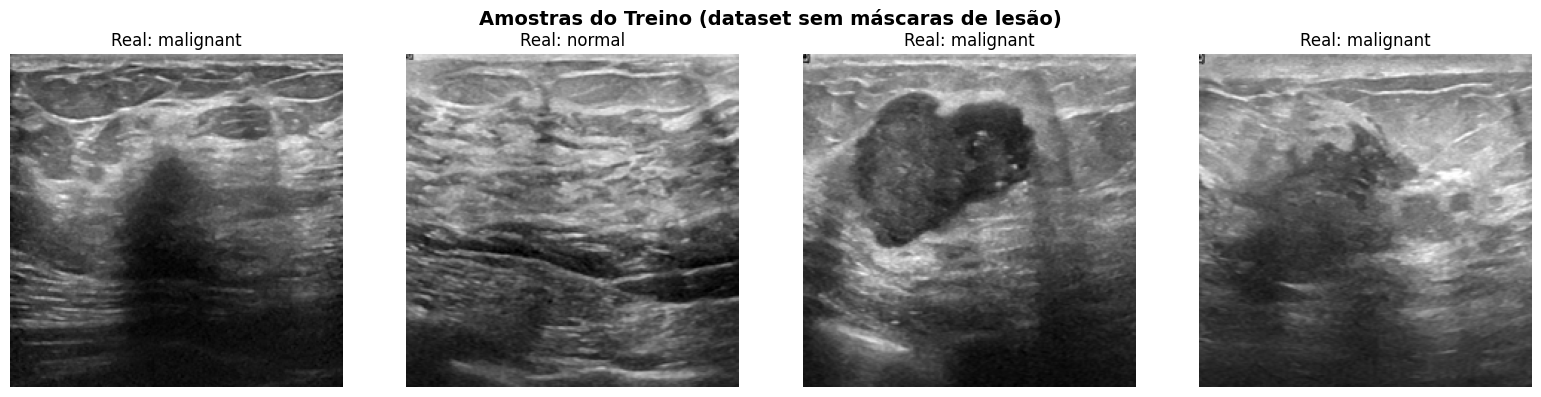

Nota: o dataset fornecido não inclui máscaras de lesão.
      O XAI será avaliado qualitativamente no Notebook 03.


In [ ]:
classes_nomes = {0: 'benign', 1: 'malignant', 2: 'normal'}
np.random.seed(42)
idx_amostra = np.random.choice(len(x_train), 4, replace=False)

if tem_mascaras_reais:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for col, idx in enumerate(idx_amostra):
        img = x_train[idx].squeeze()
        mask = m_train[idx].squeeze()
        label = y_train[idx]

        axes[0, col].imshow(img, cmap='gray')
        axes[0, col].set_title(f"Real: {classes_nomes[label]}")
        axes[0, col].axis('off')

        axes[1, col].imshow(mask, cmap='gray')
        axes[1, col].set_title(f"Máscara (soma={int(mask.sum())})")
        axes[1, col].axis('off')

    plt.suptitle("Amostras do Treino: Imagem (topo) vs Máscara (baixo)",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    # Só imagens
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for col, idx in enumerate(idx_amostra):
        img = x_train[idx].squeeze()
        label = y_train[idx]
        axes[col].imshow(img, cmap='gray')
        axes[col].set_title(f"Real: {classes_nomes[label]}")
        axes[col].axis('off')
    plt.suptitle("Amostras do Treino (dataset sem máscaras de lesão)",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print("Nota: o dataset fornecido não inclui máscaras de lesão.")
    print("      O XAI será avaliado qualitativamente no Notebook 03.")

## 6. Guardar Dados Processados (.npz)

Para evitar carregar e processar as 780 imagens de cada vez que abrimos o Colab, vamos guardar os arrays divididos em ficheiros `.npz` no Drive.

**Cada ficheiro agora tem 3 chaves:**
- `x` → imagens (N, 224, 224, 1)
- `y` → labels (N,)
- `masks` → máscaras de lesão (N, 224, 224, 1) — **novo**

O próximo notebook (treino) e o notebook 03 (XAI) irão ler estes ficheiros instantaneamente.

In [ ]:
SAVE_PATH = "/content/drive/MyDrive/Projeto/data/processado/"
os.makedirs(SAVE_PATH, exist_ok=True)

# Mantemos a chave 'masks' para compatibilidade com o NB02 já treinado
np.savez_compressed(os.path.join(SAVE_PATH, "train_data.npz"),
                    x=x_train, y=y_train, masks=m_train)
np.savez_compressed(os.path.join(SAVE_PATH, "val_data.npz"),
                    x=x_val,   y=y_val,   masks=m_val)
np.savez_compressed(os.path.join(SAVE_PATH, "test_data.npz"),
                    x=x_test,  y=y_test,  masks=m_test)

# Metadados que o NB03 vai ler para decidir o modo de avaliação do XAI
meta = {
    "tem_mascaras_reais": bool(tem_mascaras_reais),
    "n_masks_encontradas": int(n_masks_encontradas),
    "n_masks_vazias": int(n_masks_vazias),
    "img_size": IMG_SIZE,
    "classes": ["benign", "malignant", "normal"],
    "n_train": int(len(y_train)),
    "n_val":   int(len(y_val)),
    "n_test":  int(len(y_test)),
    "nota_xai": (
        "Avaliação qualitativa do Grad-CAM (alinhamento visual heatmap vs ROI) "
        "porque o dataset não fornece máscaras de lesão."
        if not tem_mascaras_reais else
        "Avaliação quantitativa do Grad-CAM (IoU/Dice) possível."
    )
}
with open(os.path.join(SAVE_PATH, "meta.json"), "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print(f" Dados guardados em '{SAVE_PATH}'")
print("Ficheiros criados:")
print("  - train_data.npz")
print("  - val_data.npz")
print("  - test_data.npz")
print("  - meta.json  ← diz ao NB03 como avaliar o XAI")
print(f"\nmeta['tem_mascaras_reais'] = {meta['tem_mascaras_reais']}")
print(f"meta['nota_xai'] = {meta['nota_xai']}")

 Dados guardados em '/content/drive/MyDrive/Projeto/data/processado/'
Ficheiros criados:
  - train_data.npz
  - val_data.npz
  - test_data.npz
  - meta.json  ← diz ao NB03 como avaliar o XAI

meta['tem_mascaras_reais'] = False
meta['nota_xai'] = Avaliação qualitativa do Grad-CAM (alinhamento visual heatmap vs ROI) porque o dataset não fornece máscaras de lesão.


## 7. Verificação Final

Confirmamos que os ficheiros `.npz` foram bem guardados e que a chave `masks` está presente.

In [ ]:
print("Verificação dos ficheiros guardados:\n")

for nome in ["train_data.npz", "val_data.npz", "test_data.npz"]:
    d = np.load(os.path.join(SAVE_PATH, nome))
    chaves = list(d.keys())
    x, y = d['x'], d['y']
    m = d['masks'] if 'masks' in chaves else None

    print(f" {nome}")
    print(f"   Chaves: {chaves}")
    print(f"   x: {x.shape} | dtype={x.dtype} | min/max={x.min():.2f}/{x.max():.2f}")
    print(f"   y: {y.shape} | classes={np.unique(y).tolist()}")

    if m is not None:
        n_com_lesao = int((m.sum(axis=(1, 2, 3)) > 0).sum())
        print(f"   masks: {m.shape} | máscaras com lesão: {n_com_lesao}/{len(m)}")
    print()

# Ler meta.json e decidir
with open(os.path.join(SAVE_PATH, "meta.json")) as f:
    meta = json.load(f)

print("=" * 60)
if meta["tem_mascaras_reais"]:
    print("  Máscaras reais disponíveis → NB03 pode calcular IoU/Dice.")
else:
    print("   Dataset SEM máscaras de lesão.")
    print("    → NB03 fará avaliação QUALITATIVA do Grad-CAM.")
    print("    → A chave 'masks' nos .npz fica a zero (compatibilidade com NB02).")
print("=" * 60)
print("\n Próximo passo: abrir 03_Active_Learning_e_XAI.ipynb")

Verificação dos ficheiros guardados:

 train_data.npz
   Chaves: ['x', 'y', 'masks']
   x: (546, 224, 224, 1) | dtype=float32 | min/max=0.00/1.00
   y: (546,) | classes=[0, 1, 2]
   masks: (546, 224, 224, 1) | máscaras com lesão: 0/546

 val_data.npz
   Chaves: ['x', 'y', 'masks']
   x: (117, 224, 224, 1) | dtype=float32 | min/max=0.00/1.00
   y: (117,) | classes=[0, 1, 2]
   masks: (117, 224, 224, 1) | máscaras com lesão: 0/117

 test_data.npz
   Chaves: ['x', 'y', 'masks']
   x: (117, 224, 224, 1) | dtype=float32 | min/max=0.00/1.00
   y: (117,) | classes=[0, 1, 2]
   masks: (117, 224, 224, 1) | máscaras com lesão: 0/117

   Dataset SEM máscaras de lesão.
    → NB03 fará avaliação QUALITATIVA do Grad-CAM.
    → A chave 'masks' nos .npz fica a zero (compatibilidade com NB02).

 Próximo passo: abrir 03_Active_Learning_e_XAI.ipynb


In [ ]:
import os
PATH = "/content/drive/MyDrive/Projeto/data/img"
todos = os.listdir(PATH)
com_mask = [f for f in todos if "mask" in f.lower()]

print(f"Total de ficheiros na pasta: {len(todos)}")
print(f"Ficheiros com 'mask' no nome: {len(com_mask)}")
print("\nPrimeiros 10 ficheiros na pasta:")
for f in todos[:10]:
    print(" -", f)

Total de ficheiros na pasta: 780
Ficheiros com 'mask' no nome: 0

Primeiros 10 ficheiros na pasta:
 - normal (27).png
 - normal (109).png
 - normal (61).png
 - normal (83).png
 - normal (123).png
 - normal (56).png
 - normal (36).png
 - normal (95).png
 - normal (31).png
 - normal (70).png


# 02 - Treino e Avaliação da CNN (Transfer Learning)

**Projeto:** Diagnóstico de Cancro da Mama com CNNs e Active Learning

Neste notebook, vamos carregar os dados pré-processados (`.npz`), construir um modelo de Deep Learning usando **Transfer Learning com a ResNet50V2** (pré-treinada no ImageNet) e avaliar o seu desempenho com métricas cruciais para a área médica — em particular o **Recall da classe Maligno** e a **Curva Precision-Recall (AUC-PR)**.

**Correções aplicadas em relação à versão anterior:**
- Pré-processamento correto com `preprocess_input` da ResNet50V2 (em vez de `x*255`).
- Conversão explícita de grayscale para RGB antes do datagen.
- Métrica de `Recall` focada na **classe Maligno** (`class_id=1`).
- Avaliação no **test set** com `classification_report`, `confusion_matrix` e `AUC-PR`.
- `ModelCheckpoint` e `EarlyStopping` monitorizam `val_recall_maligno` (o que queremos maximizar).


## 1. Carregamento dos Dados

Como guardámos os dados divididos no passo anterior, o carregamento será instantâneo e não vai consumir memória desnecessária do Colab.

**Nota importante:** os dados no `.npz` estão em `[0, 1]` com forma `(N, 224, 224, 1)`. Vamos:
1. Converter para RGB `(N, 224, 224, 3)` (a ResNet50V2 espera 3 canais).
2. Colocar em `[0, 255]` crus — o `preprocess_input` da ResNet será aplicado em tempo real pelo `ImageDataGenerator`.

In [ ]:
from google.colab import drive
import os
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import (classification_report, confusion_matrix, recall_score, precision_recall_curve, auc)
from sklearn.utils.class_weight import compute_class_weight

# Montar o Drive
drive.mount('/content/drive')
SAVE_PATH = "/content/drive/MyDrive/Projeto/data/processado/"

print("A carregar os dados...")
train_data = np.load(os.path.join(SAVE_PATH, "train_data.npz"))
val_data   = np.load(os.path.join(SAVE_PATH, "val_data.npz"))
test_data  = np.load(os.path.join(SAVE_PATH, "test_data.npz"))

x_train, y_train = train_data['x'], train_data['y']
x_val,   y_val   = val_data['x'],   val_data['y']
x_test,  y_test  = test_data['x'],  test_data['y']

# --- Conversão grayscale (N,224,224,1) -> RGB (N,224,224,3), em [0,255] ---
x_train = np.repeat(np.asarray(x_train, dtype=np.float32), 3, axis=-1) * np.float32(255.0)
x_val = np.repeat(np.asarray(x_val, dtype=np.float32), 3, axis=-1) * np.float32(255.0)
x_test = np.repeat(np.asarray(x_test, dtype=np.float32), 3, axis=-1) * np.float32(255.0)

print(f"dtype treino: {x_train.dtype}")
print(f"dtype validação: {x_val.dtype}")
print(f"dtype teste: {x_test.dtype}")

assert x_train.shape[1:] == (224, 224, 3)
assert x_val.shape[1:] == (224, 224, 3)
assert x_test.shape[1:] == (224, 224, 3)
assert x_train.dtype == np.float32

# One-hot encoding das labels
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh   = to_categorical(y_val,   num_classes=3)
y_test_oh  = to_categorical(y_test,  num_classes=3)

print(f" Dados carregados!")
print(f"   Treino:    {x_train.shape} | min/max: {x_train.min():.1f}/{x_train.max():.1f}")
print(f"   Validação: {x_val.shape}")
print(f"   Teste:     {x_test.shape}")
print(f"   Classes: benign=0 | malignant=1 | normal=2")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A carregar os dados...
dtype treino: float32
dtype validação: float32
dtype teste: float32
 Dados carregados!
   Treino:    (546, 224, 224, 3) | min/max: 0.0/255.0
   Validação: (117, 224, 224, 3)
   Teste:     (117, 224, 224, 3)
   Classes: benign=0 | malignant=1 | normal=2


## 2. Data Augmentation

Para evitar *overfitting* (o modelo decorar as imagens), aplicamos transformações (rotações, zoom, etc.) **apenas no conjunto de treino**, em tempo real.

O `preprocess_input` da ResNet50V2 é aplicado aqui — é ele que faz `x/127.5 - 1` e alinha os dados com o que a rede pré-treinada no ImageNet espera.

In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    brightness_range=(0.9, 1.1),
    fill_mode='nearest',
    preprocessing_function=preprocess_input
)

# Validação e teste: sem augmentations, mas com o mesmo preprocess_input
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

## 2.1 Diagnóstico do Pré-processamento

Antes de treinar, confirmamos que o `preprocess_input` da ResNet está a ser aplicado corretamente. Os valores devem estar aproximadamente em `[-1, 1]`. Se estiverem em `[0, 255]` ou `[0, 1]`, o pré-processamento está errado e o modelo não vai aprender.

In [ ]:
# Diagnóstico: verificar o que o datagen produz
batch_x, batch_y = next(train_datagen.flow(x_train[:8], y_train_oh[:8], batch_size=8))

print("Shape do batch:", batch_x.shape)
print(f"Min:  {batch_x.min():.4f}")
print(f"Max:  {batch_x.max():.4f}")
print(f"Mean: {batch_x.mean():.4f}")

if -1.5 < batch_x.min() < -0.5 and 0.5 < batch_x.max() < 1.5:
    print(" Pré-processamento correto (esperado ~[-1, 1])")
elif batch_x.min() >= 0 and batch_x.max() <= 1:
    print(" Dados em [0,1] — o preprocess_input NÃO está a ser aplicado!")
    print("   Verifica se x_train está em [0,255] antes do datagen.")
elif batch_x.max() > 10:
    print(" Dados em [0,255] crus — o preprocess_input NÃO está a ser aplicado!")
else:
    print(" Escala inesperada — investigar.")

Shape do batch: (8, 224, 224, 3)
Min:  -1.0000
Max:  1.0000
Mean: -0.2505
 Pré-processamento correto (esperado ~[-1, 1])


## 3. Construção do Modelo (Transfer Learning)

Usamos a **ResNet50V2** pré-treinada no ImageNet, com as camadas convolucionais congeladas. A "cabeça" de classificação é treinada de raiz para as nossas 3 classes.

**Métricas:** `accuracy` + `Recall(class_id=1)` — recall da classe **Maligno**, que é o objetivo central (minimizar falsos negativos).

**Learning rate:** `5e-4` (conservador, porque o dataset é pequeno e a base está congelada).

In [ ]:
def build_model(input_shape=(224, 224, 3), num_classes=3):
    inputs = Input(shape=input_shape)

    # Base pré-treinada, congelada
    base_model = ResNet50V2(
        include_top=False,
        weights='imagenet',
        input_shape=input_shape
    )
    base_model.trainable = False

    # Cabeça de classificação
    x = base_model(inputs)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=Adam(learning_rate=5e-4),
        loss='categorical_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Recall(class_id=1, name='recall_maligno')
        ]
    )
    return model

modelo = build_model()
modelo.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,827,459 (90.89 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

## 4. Treino

- **Callbacks:**
  - `ModelCheckpoint` guarda o melhor modelo por `val_recall_maligno`.
  - `EarlyStopping` para se `val_recall_maligno` não melhorar em 7 épocas.
- **Epochs:** 15.

**O que esperar:** a `loss` da época 1 deve estar próxima de **1.1** (valor de `-ln(1/3)`). Se estiver em dezenas/centenas, o pré-processamento está errado — volta ao diagnóstico.

In [ ]:
train_generator = train_datagen.flow(x_train, y_train_oh, batch_size=32, shuffle=True)
val_generator   = val_datagen.flow(x_val,     y_val_oh,   batch_size=32, shuffle=False)

callbacks = [
    EarlyStopping(
        monitor='val_recall_maligno',
        mode='max',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        '/content/drive/MyDrive/Projeto/melhor_modelo.keras',
        monitor='val_recall_maligno',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(enumerate(class_weights))

EPOCHS = 15
inicio = time.time()


history = modelo.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

print(f"\n Treino concluído em {(time.time()-inicio)/60:.1f} min")
print(f" Loss final (treino): {history.history['loss'][-1]:.3f}")
print(f" Melhor val_recall_maligno: {max(history.history['val_recall_maligno']):.3f}")

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.4931 - loss: 1.2061 - recall_maligno: 0.3921
Epoch 1: val_recall_maligno improved from None to 0.78125, saving model to /content/drive/MyDrive/Projeto/melhor_modelo.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Projeto/melhor_modelo.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.5458 - loss: 1.0809 - recall_maligno: 0.4354 - val_accuracy: 0.6838 - val_loss: 0.6883 - val_recall_maligno: 0.7812
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step - accuracy: 0.6558 - loss: 0.7670 - recall_maligno: 0.6102
Epoch 2: val_recall_maligno did not improve from 0.78125
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 482ms/step - accuracy: 0.6941 - loss: 0.6868 - recall_maligno: 0.6599 - val_accuracy: 0.6581 - val_loss: 0.6981 - val_recall_maligno: 0.6875
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.7263 - loss: 0.5904 - recall_maligno: 0.7121
Epoch 3: val_recall_maligno did not improve from 0.78125
1

In [ ]:
# Recuperar a ResNet50V2 incluída no modelo
base_model = modelo.get_layer("resnet50v2")

# Descongelar a base e voltar a congelar tudo,
# exceto as últimas 20 camadas
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

# Manter Batch Normalization congelada
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# É necessário recompilar depois de alterar as camadas treináveis
modelo.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Recall(
            class_id=1,
            name="recall_maligno"
        )
    ]
)

callbacks_finetune = [
    EarlyStopping(
        monitor="val_recall_maligno",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/drive/MyDrive/Projeto/melhor_modelo_finetuned.keras",
        monitor="val_recall_maligno",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

history_finetune = modelo.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=callbacks_finetune,
    class_weight=class_weight_dict
)

print(
    "Melhor recall maligno na validação durante o fine-tuning:",
    f"{max(history_finetune.history['val_recall_maligno']):.3f}"
)

Epoch 1/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.7323 - loss: 0.5184 - recall_maligno: 0.7931
Epoch 1: val_recall_maligno improved from None to 0.84375, saving model to /content/drive/MyDrive/Projeto/melhor_modelo_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Projeto/melhor_modelo_finetuned.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.7692 - loss: 0.4733 - recall_maligno: 0.7415 - val_accuracy: 0.8291 - val_loss: 0.4896 - val_recall_maligno: 0.8438
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.8148 - loss: 0.4039 - recall_maligno: 0.8841
Epoch 2: val_recall_maligno did not improve from 0.84375
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 451ms/step - accuracy: 0.8077 - loss: 0.4058 - recall_maligno: 0.8707 - val_accuracy: 0.8376 - val_loss: 0.4758 - val_recall_maligno: 0.7188
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.8200 - loss: 0.3292 - recall_maligno: 0.7910
Epoch 3: val_recall_maligno did not im

## 4.1 Fine-tuning das camadas finais

Depois de treinar a cabeça de classificação com a base ResNet50V2 congelada, descongelamos apenas algumas camadas finais e treinamos novamente com uma taxa de aprendizagem mais baixa. As camadas Batch Normalization permanecem congeladas para reduzir a instabilidade num dataset pequeno.

A validação é usada para acompanhar esta experiência. O conjunto de teste não é usado para escolher épocas, parâmetros ou modelos.

In [ ]:
print(
    "Recall maligno na validação — modelo inicial:",
    f"{max(history.history['val_recall_maligno']):.3f}"
)

print(
    "Recall maligno na validação — fine-tuning:",
    f"{max(history_finetune.history['val_recall_maligno']):.3f}"
)

Recall maligno na validação — modelo inicial: 0.875
Recall maligno na validação — fine-tuning: 0.844


## 5. Gráficos de Evolução

Visualizamos a evolução de `accuracy`, `loss` e `recall_maligno` ao longo das épocas, para treino e validação.

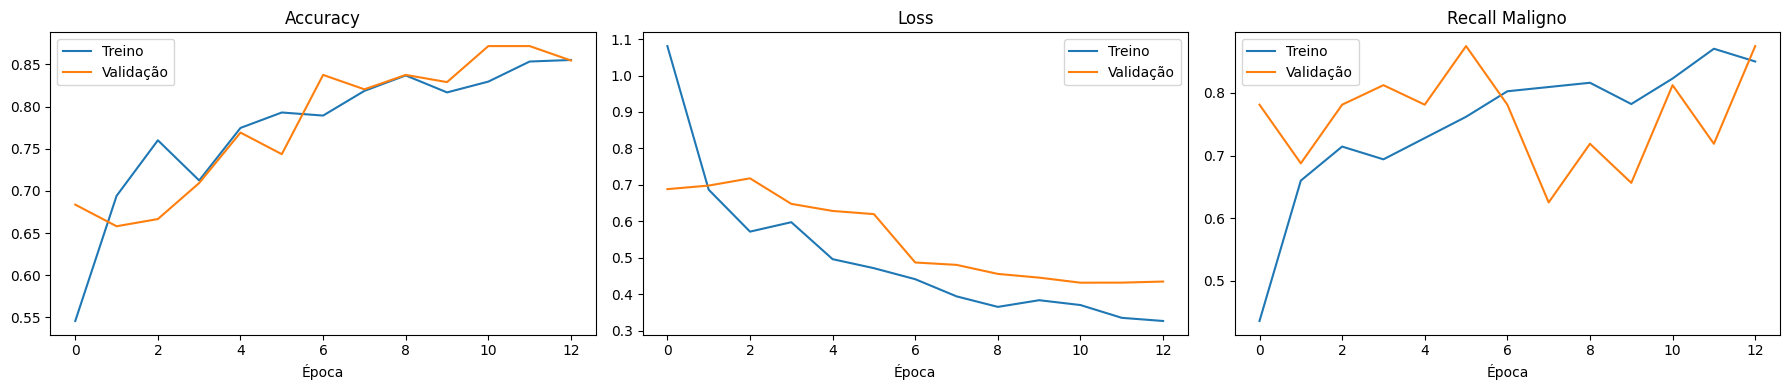

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Treino')
axes[0].plot(history.history['val_accuracy'], label='Validação')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Época')
axes[0].legend()

# Loss
axes[1].plot(history.history['loss'],     label='Treino')
axes[1].plot(history.history['val_loss'], label='Validação')
axes[1].set_title('Loss')
axes[1].set_xlabel('Época')
axes[1].legend()

# Recall Maligno
axes[2].plot(history.history['recall_maligno'],     label='Treino')
axes[2].plot(history.history['val_recall_maligno'], label='Validação')
axes[2].set_title('Recall Maligno')
axes[2].set_xlabel('Época')
axes[2].legend()

plt.tight_layout()
plt.show()

## 6. Avaliação no Test Set

> **Importante:** o `predict` aplica `preprocess_input` aos dados de teste, para que fiquem na mesma escala que os dados de treino (que passaram pelo `ImageDataGenerator` com `preprocessing_function=preprocess_input`). **Sem isto, a avaliação é inválida.**

Métricas:
- `classification_report` por classe.
- Recall da classe Maligno.
- Matriz de confusão.
- Curva Precision-Recall (AUC-PR) da classe Maligno.

> `benign=0 | malignant=1 | normal=2`

In [ ]:
# Carregar o melhor modelo guardado
melhor_modelo = tf.keras.models.load_model(
    '/content/drive/MyDrive/Projeto/melhor_modelo.keras'
)

#  CRÍTICO: aplicar preprocess_input aos dados de teste (igual ao datagen do treino)
x_test_pre = preprocess_input(x_test.copy())

print(f" Teste pré-processado: min={x_test_pre.min():.2f} | max={x_test_pre.max():.2f}")
# Deve dar ~-1 a ~1

# Previsões
y_pred_prob = melhor_modelo.predict(x_test_pre, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)

# --- Classification Report ---
print("\n" + "="*60)
print("CLASSIFICATION REPORT (Test Set)")
print("="*60)
print(classification_report(
    y_test, y_pred,
    target_names=['benign', 'malignant', 'normal'],
    digits=3,
    zero_division=0
))

# --- Recall da classe Maligno ---
recall_mal = recall_score(y_test, y_pred, labels=[1], average=None)[0]
print(f"\n Recall da classe Maligno (test set): {recall_mal:.3f}")

 Teste pré-processado: min=-1.00 | max=1.00

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

      benign      0.919     0.515     0.660        66
   malignant      0.438     0.903     0.589        31
      normal      0.688     0.550     0.611        20

    accuracy                          0.624       117
   macro avg      0.681     0.656     0.620       117
weighted avg      0.752     0.624     0.633       117


 Recall da classe Maligno (test set): 0.903


Matriz de confusão

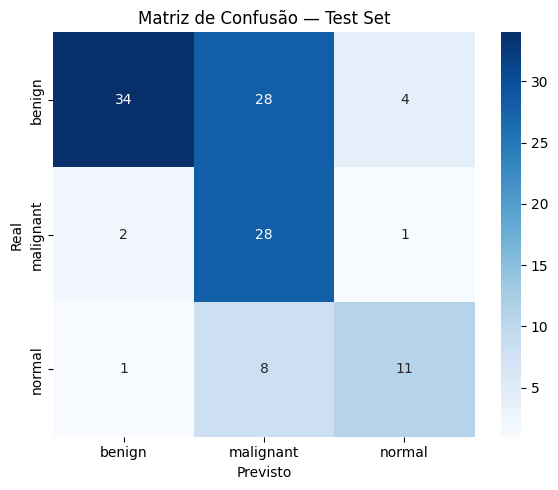

 Falsos negativos (Maligno previsto como outra classe): 3/31


In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['benign', 'malignant', 'normal'],
    yticklabels=['benign', 'malignant', 'normal']
)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão — Test Set')
plt.tight_layout()
plt.show()

# Falsos negativos da classe Maligno
fn_maligno    = cm[1, 0] + cm[1, 2]
total_maligno = cm[1, :].sum()
print(f" Falsos negativos (Maligno previsto como outra classe): "
      f"{fn_maligno}/{total_maligno}")

Curva Precision-Recall

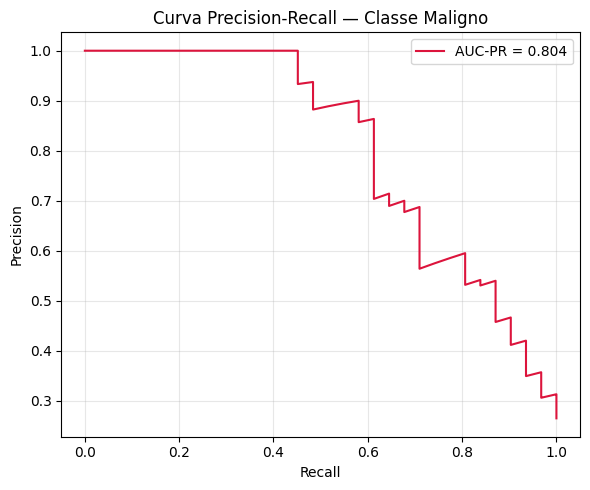

 AUC-PR (Maligno): 0.804


In [ ]:
prec, rec, _ = precision_recall_curve(y_test == 1, y_pred_prob[:, 1])
auc_pr = auc(rec, prec)

plt.figure(figsize=(6, 5))
plt.plot(rec, prec, label=f'AUC-PR = {auc_pr:.3f}', color='crimson')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall — Classe Maligno')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f" AUC-PR (Maligno): {auc_pr:.3f}")

In [ ]:
import numpy as np
import os

SAVE_PATH = "/content/drive/MyDrive/Projeto/data/processado/"
test_data = np.load(os.path.join(SAVE_PATH, "test_data.npz"))

print("O que está guardado no meu ficheiro de teste?")
print(list(test_data.keys()))

O que está guardado no meu ficheiro de teste?
['x', 'y', 'masks']


# 03 — Explicabilidade (Grad-CAM) e Active Learning

Este notebook avalia o modelo de classificação de imagens de ultrassom, gera visualizações Grad-CAM e executa uma simulação de Active Learning sem usar o conjunto de teste durante a seleção ou o treino.

**Limites:** é um trabalho académico e experimental. As previsões não são diagnóstico médico nem devem orientar decisões clínicas. A simulação de Active Learning usa os rótulos do dataset como substituto de uma anotação humana; não é uma avaliação real por médicos.


In [1]:
# 1. Imports, reprodutibilidade e ligação ao Google Drive
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Montar o Drive
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/Projeto"
DATA_PATH = os.path.join(BASE, "data", "processado")
TRAIN_PATH = os.path.join(DATA_PATH, "train_data.npz")
VAL_PATH = os.path.join(DATA_PATH, "val_data.npz")
TEST_PATH = os.path.join(DATA_PATH, "test_data.npz")
MODEL_PATH = os.path.join(BASE, "melhor_modelo.keras")

CLASSES = ["benign", "malignant", "normal"]
N_CLASSES = len(CLASSES)


Mounted at /content/drive


## 1. Dados e modelo de referência

Carregamos treino e validação para a experiência de Active Learning e para a inspeção qualitativa do Grad-CAM. O teste só será carregado na última secção, depois de estarem concluídas as escolhas do modelo e da estratégia.

O modelo de referência é o checkpoint treinado no Notebook 02. Para usar o modelo com fine-tuning, altere `MODEL_PATH` na célula anterior para o checkpoint correspondente — e faça essa escolha com base na validação, não no teste.


In [2]:
# Carregar os conjuntos de treino e validação e o modelo de referência
for path in (TRAIN_PATH, VAL_PATH, MODEL_PATH):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Ficheiro necessário não encontrado: {path}")

train_data = np.load(TRAIN_PATH)
val_data = np.load(VAL_PATH)

x_train_all = np.asarray(train_data["x"], dtype=np.float32)
y_train_all = np.asarray(train_data["y"], dtype=np.int64)
x_val = np.asarray(val_data["x"], dtype=np.float32)
y_val = np.asarray(val_data["y"], dtype=np.int64)


def to_rgb255(images_gray):
    """Converte imagens (N, H, W, 1) em RGB float32 na escala [0, 255]."""
    images_gray = np.asarray(images_gray, dtype=np.float32)
    if images_gray.ndim != 4 or images_gray.shape[-1] != 1:
        raise ValueError(
            f"Esperava imagens (N, H, W, 1), recebi {images_gray.shape}"
        )
    return np.repeat(images_gray, 3, axis=-1) * np.float32(255.0)


x_val_rgb = to_rgb255(x_val)
x_val_pre = preprocess_input(x_val_rgb.copy())
y_val_oh = to_categorical(y_val, num_classes=N_CLASSES)

baseline_model = tf.keras.models.load_model(MODEL_PATH)

print("Treino:", x_train_all.shape, x_train_all.dtype)
print("Validação:", x_val.shape, x_val.dtype)
print("Modelo de referência carregado:", MODEL_PATH)
print("Rótulos:", dict(enumerate(CLASSES)))


Treino: (546, 224, 224, 1) float32
Validação: (117, 224, 224, 1) float32
Modelo de referência carregado: /content/drive/MyDrive/Projeto/melhor_modelo.keras
Rótulos: {0: 'benign', 1: 'malignant', 2: 'normal'}


## 2. Funções Grad-CAM

A camada convolucional final é usada para produzir o mapa de ativação. As camadas seguintes são reaplicadas pela ordem do próprio modelo, sem depender de nomes automáticos como `dense_2` ou `global_average_pooling2d_1`, que podem mudar entre sessões.


In [3]:
# Encontrar a ResNet dentro do modelo e construir a versão plana para Grad-CAM
base_model = next(
    (
        layer for layer in baseline_model.layers
        if hasattr(layer, "layers") and "resnet" in layer.name.lower()
    ),
    None,
)
if base_model is None:
    raise ValueError("Não foi encontrada a ResNet dentro do modelo carregado.")

last_conv = "conv5_block3_out"
if last_conv not in [layer.name for layer in base_model.layers]:
    raise ValueError(f"A camada {last_conv!r} não existe na ResNet carregada.")

flat_input = base_model.input
x = base_model.output
after_backbone = False
for layer in baseline_model.layers:
    if layer is base_model:
        after_backbone = True
        continue
    if after_backbone:
        x = layer(x)

if not after_backbone:
    raise ValueError("Não foi possível ligar a cabeça do classificador à ResNet.")

flat_model = tf.keras.models.Model(
    inputs=flat_input,
    outputs=x,
    name="flat_model_for_gradcam",
)
print("Modelo Grad-CAM:", flat_model.input.shape, "→", flat_model.output.shape)


def make_gradcam_heatmap(
    img_array,
    flat_model,
    base_model,
    last_conv_layer_name,
    pred_index=None,
):
    """Gera um heatmap Grad-CAM para uma imagem pré-processada em batch."""
    grad_model = tf.keras.models.Model(
        inputs=flat_model.input,
        outputs=[
            base_model.get_layer(last_conv_layer_name).output,
            flat_model.output,
        ],
    )

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(predictions[0]).numpy())
        class_score = predictions[:, pred_index]

    gradients = tape.gradient(class_score, conv_output)
    if gradients is None:
        raise RuntimeError("Não foi possível calcular os gradientes do Grad-CAM.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = conv_output[0] @ weights[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-9)
    return heatmap.numpy()


def overlay_heatmap(img, heatmap, alpha=0.4):
    """Sobrepõe o heatmap numa imagem cinzenta [0,1] ou [0,255]."""
    img = np.asarray(img).squeeze()
    if img.ndim == 2:
        img_rgb = np.stack([img] * 3, axis=-1)
    elif img.ndim == 3 and img.shape[-1] == 3:
        img_rgb = img
    else:
        raise ValueError(f"Formato de imagem não suportado: {img.shape}")

    if np.issubdtype(img_rgb.dtype, np.floating) and img_rgb.max() <= 1.0:
        img_rgb = img_rgb * 255.0
    img_rgb = np.uint8(np.clip(img_rgb, 0, 255))

    heatmap = np.asarray(heatmap, dtype=np.float32)
    heatmap_resized = cv2.resize(heatmap, (img_rgb.shape[1], img_rgb.shape[0]))
    heatmap_uint8 = np.uint8(255 * np.clip(heatmap_resized, 0, 1))
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    return cv2.addWeighted(img_rgb, 1 - alpha, heatmap_color, alpha, 0)


Modelo Grad-CAM: (None, 224, 224, 3) → (None, 3)


## 3. Inspeção visual do Grad-CAM

Os mapas seguintes usam imagens da validação, não do teste. São visualizações exploratórias: mostram regiões que influenciaram a previsão do modelo, mas não provam que o modelo encontrou a lesão nem explicam causalmente a decisão.


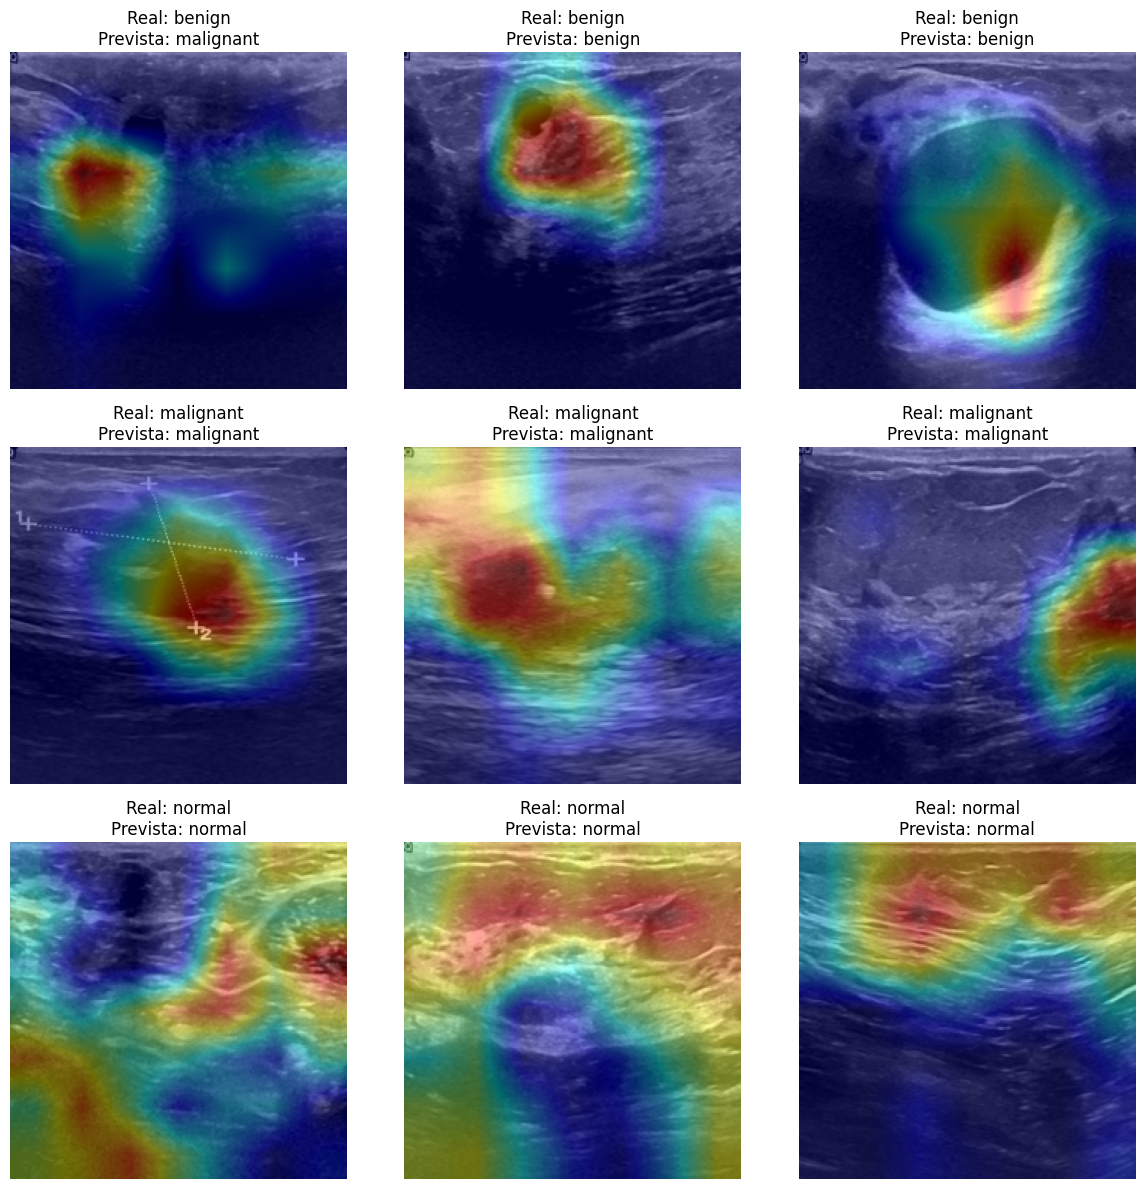

In [4]:
# Gerar exemplos de validação: até 3 imagens por classe
val_probs = baseline_model.predict(x_val_pre, verbose=0)
val_pred = np.argmax(val_probs, axis=1)

fig, axes = plt.subplots(N_CLASSES, 3, figsize=(12, 12))
for class_id, class_name in enumerate(CLASSES):
    indices = np.where(y_val == class_id)[0][:3]
    for col in range(3):
        ax = axes[class_id, col]
        ax.axis("off")
        if col >= len(indices):
            continue

        idx = indices[col]
        img_batch = np.expand_dims(x_val_pre[idx], axis=0)
        predicted_class = int(val_pred[idx])
        heatmap = make_gradcam_heatmap(
            img_batch,
            flat_model,
            base_model,
            last_conv,
            pred_index=predicted_class,
        )
        overlay = overlay_heatmap(x_val[idx], heatmap)
        ax.imshow(overlay)
        ax.set_title(
            f"Real: {class_name}\nPrevista: {CLASSES[predicted_class]}"
        )

plt.tight_layout()
plt.show()


## 4. Avaliação qualitativa por especialista

O dataset carregado não contém máscaras de lesão, por isso este notebook não calcula IoU ou Dice. Também não usa a percentagem de ativação na região central como medida de confiança: a lesão não tem de estar no centro da imagem.

Se um médico ou especialista puder rever os exemplos, peça-lhe que avalie cada mapa com critérios definidos previamente, por exemplo: relevância da região realçada, dispersão do mapa e presença de artefactos. Registem a avaliação; não a substituam por um “médico perfeito” simulado com acesso aos rótulos verdadeiros.


In [5]:
# Modelo de tabela para registar a revisão qualitativa
xai_review_template = pd.DataFrame(
    columns=[
        "indice_validacao",
        "classe_real_dataset",
        "classe_prevista_IA",
        "relevancia_gradcam_1a5",
        "mapa_disperso_1a5",
        "artefactos_observados",
        "comentario_especialista",
    ]
)
display(xai_review_template)


,indice_validacao,classe_real_dataset,classe_prevista_IA,relevancia_gradcam_1a5,mapa_disperso_1a5,artefactos_observados,comentario_especialista


## 5. Active Learning — protocolo da simulação

Para evitar leakage, a seed e a pool são criadas **dentro do conjunto de treino**. O modelo começa de novo e aprende inicialmente apenas com a seed. Em cada ronda, seleciona imagens da pool; nesta simulação, o rótulo verdadeiro do dataset funciona como substituto da anotação humana, apenas para os casos selecionados.

A validação acompanha o desempenho. O teste não é usado para selecionar imagens, treinar, definir limiares ou escolher a estratégia. São comparadas duas políticas: seleção aleatória e seleção por incerteza MC Dropout.


In [6]:
# Arquitetura independente para as experiências de Active Learning

def build_al_model():
    inputs = Input(shape=(224, 224, 3))
    backbone = ResNet50V2(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3),
    )
    backbone.trainable = False

    # Mantém a ResNet em modo de inferência; o Dropout da cabeça pode variar
    x = backbone(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.3)(x)
    outputs = Dense(N_CLASSES, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=5e-4),
        loss="categorical_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Recall(class_id=1, name="recall_maligno"),
        ],
    )
    return model


al_train_datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    brightness_range=(0.9, 1.1),
    fill_mode="nearest",
    preprocessing_function=preprocess_input,
)



In [7]:
def mc_dropout_entropy(model, pool_gray, n_passes=5, batch_size=16):
    """Calcula entropia preditiva por batches para imagens não rotuladas."""
    pool_rgb = to_rgb255(pool_gray)
    entropies = np.zeros(len(pool_rgb), dtype=np.float32)

    for start in range(0, len(pool_rgb), batch_size):
        end = min(start + batch_size, len(pool_rgb))
        batch = preprocess_input(pool_rgb[start:end].copy())
        pass_probs = [
            model(batch, training=True).numpy()
            for _ in range(n_passes)
        ]
        mean_probs = np.mean(np.stack(pass_probs, axis=0), axis=0)
        mean_probs = np.clip(mean_probs, 1e-9, 1.0)
        entropies[start:end] = -np.sum(
            mean_probs * np.log(mean_probs), axis=1
        )

    return entropies


def class_weights_for_labels(y):
    present_classes = np.unique(y)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=present_classes,
        y=y,
    )
    return {
        int(class_id): float(weight)
        for class_id, weight in zip(present_classes, weights)
    }


def run_active_learning(
    strategy,
    seed=42,
    initial_fraction=0.20,
    query_size=10,
    n_rounds=3,
    epochs_per_round=6,
    mc_passes=5,
):
    """Corre AL com pool retirada do treino e validação separada."""
    if strategy not in {"random", "uncertainty"}:
        raise ValueError("strategy deve ser 'random' ou 'uncertainty'.")

    tf.keras.utils.set_random_seed(seed)
    indices = np.arange(len(y_train_all))
    idx_seed, idx_pool = train_test_split(
        indices,
        test_size=1 - initial_fraction,
        stratify=y_train_all,
        random_state=seed,
    )

    x_labeled = x_train_all[idx_seed].copy()
    y_labeled = y_train_all[idx_seed].copy()
    x_pool = x_train_all[idx_pool].copy()
    y_pool_oracle = y_train_all[idx_pool].copy()

    model_al = build_al_model()
    records = []
    rng = np.random.default_rng(seed)

    for round_number in range(n_rounds + 1):
        x_labeled_rgb = to_rgb255(x_labeled)
        y_labeled_oh = to_categorical(y_labeled, num_classes=N_CLASSES)
        train_flow = al_train_datagen.flow(
            x_labeled_rgb,
            y_labeled_oh,
            batch_size=32,
            shuffle=True,
            seed=seed + round_number,
        )

        model_al.fit(
            train_flow,
            validation_data=(x_val_pre, y_val_oh),
            epochs=epochs_per_round,
            callbacks=[
                EarlyStopping(
                    monitor="val_recall_maligno",
                    mode="max",
                    patience=2,
                    restore_best_weights=True,
                    verbose=0,
                )
            ],
            class_weight=class_weights_for_labels(y_labeled),
            verbose=0,
        )

        val_probabilities = model_al.predict(x_val_pre, verbose=0)
        val_predictions = np.argmax(val_probabilities, axis=1)
        val_recall_malignant = recall_score(
            y_val,
            val_predictions,
            labels=[1],
            average=None,
            zero_division=0,
        )[0]

        records.append(
            {
                "estrategia": strategy,
                "ronda": round_number,
                "imagens_rotuladas": len(y_labeled),
                "recall_maligno_validacao": float(val_recall_malignant),
                "accuracy_validacao": float(
                    accuracy_score(y_val, val_predictions)
                ),
            }
        )
        print(
            f"{strategy} | ronda {round_number} | "
            f"rotuladas={len(y_labeled)} | "
            f"recall maligno validação={val_recall_malignant:.3f}"
        )

        if round_number == n_rounds or len(x_pool) == 0:
            break

        k = min(query_size, len(x_pool))
        if strategy == "uncertainty":
            scores = mc_dropout_entropy(
                model_al,
                x_pool,
                n_passes=mc_passes,
            )
            query_local = np.argsort(scores)[-k:]
        else:
            query_local = rng.choice(len(x_pool), size=k, replace=False)

        # Simulação: revelar apenas os rótulos dos casos selecionados
        x_labeled = np.concatenate(
            [x_labeled, x_pool[query_local]], axis=0
        )
        y_labeled = np.concatenate(
            [y_labeled, y_pool_oracle[query_local]], axis=0
        )

        keep = np.ones(len(x_pool), dtype=bool)
        keep[query_local] = False
        x_pool = x_pool[keep]
        y_pool_oracle = y_pool_oracle[keep]

    return model_al, pd.DataFrame(records)


### Executar as duas políticas

Esta simulação treina modelos novos; não reutiliza o checkpoint treinado com todo o conjunto de treino. Pode demorar alguns minutos, dependendo do hardware disponível.


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
random | ronda 0 | rotuladas=109 | recall maligno validação=0.781
random | ronda 1 | rotuladas=119 | recall maligno validação=0.750
random | ronda 2 | rotuladas=129 | recall maligno validação=0.719
random | ronda 3 | rotuladas=139 | recall maligno validação=0.719
uncertainty | ronda 0 | rotuladas=109 | recall maligno validação=0.781
uncertainty | ronda 1 | rotuladas=119 | recall maligno validação=0.781
uncertainty | ronda 2 | rotuladas=129 | recall maligno validação=0.719
uncertainty | ronda 3 | rotuladas=139 | recall maligno validação=0.719


,estrategia,ronda,imagens_rotuladas,recall_maligno_validacao,accuracy_validacao
0,random,0,109,0.78125,0.598291
1,random,1,119,0.75000,0.683761
2,random,2,129,0.71875,0.717949
3,random,3,139,0.71875,0.658120
4,uncertainty,0,109,0.78125,0.598291
5,uncertainty,1,119,0.78125,0.675214
6,uncertainty,2,129,0.71875,0.726496
7,uncertainty,3,139,0.71875,0.760684


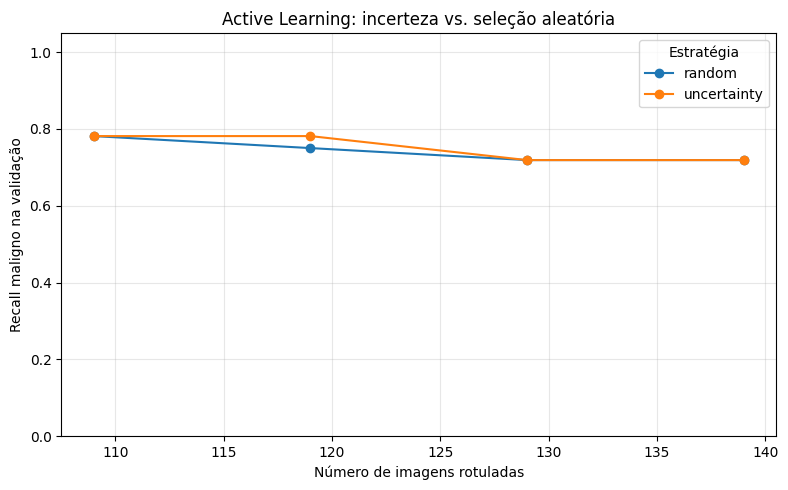

In [8]:
model_random, log_random = run_active_learning(
    strategy="random",
    seed=SEED,
)

model_uncertainty, log_uncertainty = run_active_learning(
    strategy="uncertainty",
    seed=SEED,
)

al_results = pd.concat(
    [log_random, log_uncertainty],
    ignore_index=True,
)
display(al_results)

plt.figure(figsize=(8, 5))
for strategy, group in al_results.groupby("estrategia"):
    plt.plot(
        group["imagens_rotuladas"],
        group["recall_maligno_validacao"],
        marker="o",
        label=strategy,
    )
plt.xlabel("Número de imagens rotuladas")
plt.ylabel("Recall maligno na validação")
plt.title("Active Learning: incerteza vs. seleção aleatória")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend(title="Estratégia")
plt.tight_layout()
plt.show()


## 6. Avaliação final no teste

Executar esta secção apenas depois de concluídas as decisões de treino e de estratégia. O teste não deve ser usado para voltar a ajustar o modelo. As estratégias aleatória e de incerteza são reportadas como comparação planeada, não escolhidas com base no teste.



ResNet50V2 (Notebook 02)
              precision    recall  f1-score   support

      benign      0.919     0.515     0.660        66
   malignant      0.438     0.903     0.589        31
      normal      0.688     0.550     0.611        20

    accuracy                          0.624       117
   macro avg      0.681     0.656     0.620       117
weighted avg      0.752     0.624     0.633       117


Active Learning aleatório
              precision    recall  f1-score   support

      benign      0.900     0.545     0.679        66
   malignant      0.533     0.774     0.632        31
      normal      0.562     0.900     0.692        20

    accuracy                          0.667       117
   macro avg      0.665     0.740     0.668       117
weighted avg      0.745     0.667     0.669       117


Active Learning por incerteza
              precision    recall  f1-score   support

      benign      0.791     0.803     0.797        66
   malignant      0.571     0.645     0.606  

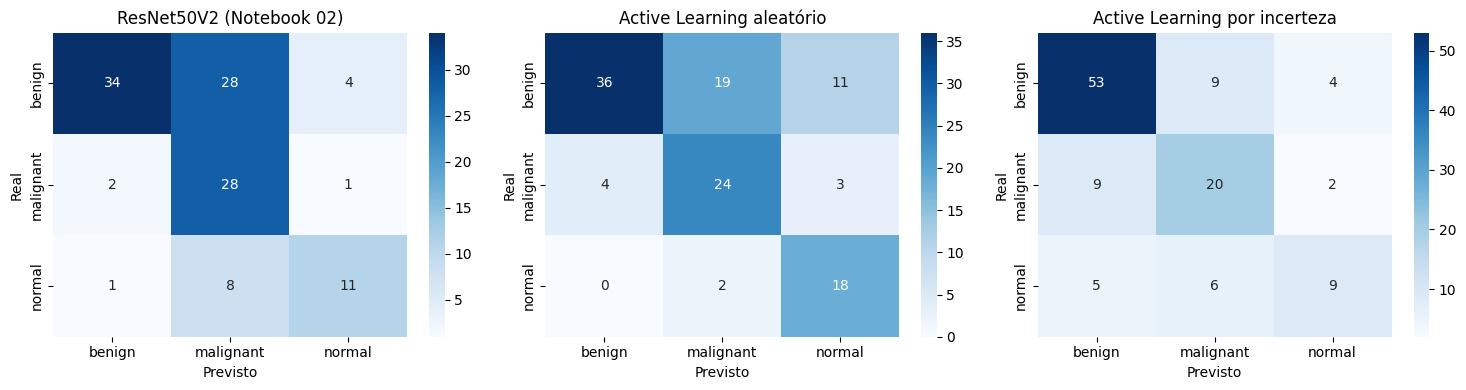

,modelo,accuracy,recall_maligno,average_precision_maligno
0,ResNet50V2 (Notebook 02),0.623932,0.903226,0.805840
1,Active Learning aleatório,0.666667,0.774194,0.759258
2,Active Learning por incerteza,0.700855,0.645161,0.683493


In [9]:
# Carregar o teste apenas para a avaliação final
if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(f"Ficheiro de teste não encontrado: {TEST_PATH}")

test_data = np.load(TEST_PATH)
x_test = np.asarray(test_data["x"], dtype=np.float32)
y_test = np.asarray(test_data["y"], dtype=np.int64)
x_test_pre = preprocess_input(to_rgb255(x_test))

models_to_evaluate = {
    "ResNet50V2 (Notebook 02)": baseline_model,
    "Active Learning aleatório": model_random,
    "Active Learning por incerteza": model_uncertainty,
}

final_results = []
fig, axes = plt.subplots(1, len(models_to_evaluate), figsize=(15, 4))

for ax, (model_name, evaluated_model) in zip(axes, models_to_evaluate.items()):
    probabilities = evaluated_model.predict(x_test_pre, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    malignant_recall = recall_score(
        y_test,
        predictions,
        labels=[1],
        average=None,
        zero_division=0,
    )[0]
    malignant_ap = average_precision_score(
        (y_test == 1).astype(np.int32),
        probabilities[:, 1],
    )

    final_results.append(
        {
            "modelo": model_name,
            "accuracy": accuracy_score(y_test, predictions),
            "recall_maligno": malignant_recall,
            "average_precision_maligno": malignant_ap,
        }
    )

    cm = confusion_matrix(y_test, predictions, labels=[0, 1, 2])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

    print(f"\n{model_name}")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=CLASSES,
            digits=3,
            zero_division=0,
        )
    )

plt.tight_layout()
plt.show()

display(pd.DataFrame(final_results))


## 7. Interpretação, limites e participação do médico

- A seleção aleatória e a seleção por incerteza usam rótulos do dataset para simular a anotação. Isto não é feedback real de um médico.
- Para uma avaliação com especialista, registar primeiro a leitura independente do médico; depois mostrar a previsão e o Grad-CAM; finalmente registar se a opinião mudou e porquê.
- Comparar médico sozinho, IA sozinha e médico com IA contra os rótulos de referência do dataset. Se houver apenas um médico ou poucos casos, descrever como avaliação exploratória, não validação clínica.
- O recall, a precisão e a AUC-PR neste dataset não demonstram segurança clínica. O sistema é um protótipo académico e não deve ser usado para diagnosticar pacientes.
- O teste contém poucos casos malignos; reportar o número de casos e os falsos negativos, não apenas percentagens.


## 8. Preparar os utilitários para um protótipo Flask

Esta célula cria os ficheiros auxiliares no Google Drive; não inicia nem publica o servidor. O caminho do modelo é configurável no `app.py`. A aplicação é apenas uma demonstração académica, não um serviço clínico.


In [10]:
from pathlib import Path

SRC_DIR = Path(BASE) / "src"
WEB_DIR = Path(BASE) / "web_app"
TEMPLATES_DIR = WEB_DIR / "templates"
SRC_DIR.mkdir(parents=True, exist_ok=True)
TEMPLATES_DIR.mkdir(parents=True, exist_ok=True)

# Funções independentes para serem importadas pela aplicação
utils_source = r'''import cv2
import numpy as np
import tensorflow as tf


def build_flat_model(model):
    base_model = next(
        (layer for layer in model.layers
         if hasattr(layer, "layers") and "resnet" in layer.name.lower()),
        None,
    )
    if base_model is None:
        raise ValueError("ResNet não encontrada no modelo.")

    x = base_model.output
    found = False
    for layer in model.layers:
        if layer is base_model:
            found = True
            continue
        if found:
            x = layer(x)
    if not found:
        raise ValueError("Não foi possível construir a cabeça do modelo Grad-CAM.")
    return base_model, tf.keras.Model(base_model.input, x, name="flat_model")


def make_gradcam_heatmap(img_batch, flat_model, base_model, last_conv, class_id):
    grad_model = tf.keras.Model(
        flat_model.input,
        [base_model.get_layer(last_conv).output, flat_model.output],
    )
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_batch, training=False)
        score = predictions[:, class_id]
    gradients = tape.gradient(score, conv_output)
    if gradients is None:
        raise RuntimeError("Não foi possível calcular o Grad-CAM.")
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = conv_output[0] @ weights[..., tf.newaxis]
    heatmap = tf.squeeze(tf.maximum(heatmap, 0))
    heatmap /= tf.reduce_max(heatmap) + 1e-9
    return heatmap.numpy()


def overlay_heatmap(img, heatmap, alpha=0.4):
    img = np.asarray(img).squeeze()
    if img.ndim != 2:
        raise ValueError(f"Esperava imagem em escala de cinzentos, recebi {img.shape}")
    if np.issubdtype(img.dtype, np.floating) and img.max() <= 1.0:
        img = img * 255.0
    img_rgb = np.stack([np.clip(img, 0, 255).astype(np.uint8)] * 3, axis=-1)
    heatmap = cv2.resize(np.asarray(heatmap, dtype=np.float32),
                         (img_rgb.shape[1], img_rgb.shape[0]))
    heatmap_u8 = np.uint8(255 * np.clip(heatmap, 0, 1))
    color = cv2.cvtColor(
        cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET),
        cv2.COLOR_BGR2RGB,
    )
    return cv2.addWeighted(img_rgb, 1 - alpha, color, alpha, 0)
'''
(SRC_DIR / "gradcam_utils.py").write_text(utils_source, encoding="utf-8")

model_source = r'''import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.resnet_v2 import preprocess_input

CLASSES = ["benign", "malignant", "normal"]


def preparar_imagem(imagem_gray):
    imagem_gray = np.asarray(imagem_gray)
    if imagem_gray.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinzentos.")
    rgb = np.stack([imagem_gray] * 3, axis=-1).astype(np.float32)
    resized = cv2.resize(rgb, (224, 224))
    return preprocess_input(np.expand_dims(resized, axis=0))


def carregar_modelo(caminho):
    return tf.keras.models.load_model(caminho)


def prever(modelo, imagem_gray):
    img_batch = preparar_imagem(imagem_gray)
    probabilities = modelo.predict(img_batch, verbose=0)[0]
    index = int(np.argmax(probabilities))
    result = {
        "classe": CLASSES[index],
        "indice": index,
        "confianca": float(probabilities[index]),
        "probabilidades": {
            name: float(value)
            for name, value in zip(CLASSES, probabilities)
        },
    }
    return result, img_batch
'''
(SRC_DIR / "modelo.py").write_text(model_source, encoding="utf-8")

app_source = r'''import base64
import io
import os
import sys

import numpy as np
from flask import Flask, jsonify, render_template, request
from PIL import Image

PROJECT_DIR = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
sys.path.insert(0, PROJECT_DIR)

from src.gradcam_utils import build_flat_model, make_gradcam_heatmap, overlay_heatmap
from src.modelo import carregar_modelo, prever

app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 10 * 1024 * 1024
MODEL_PATH = os.environ.get(
    "MODEL_PATH",
    "/content/drive/MyDrive/Projeto/melhor_modelo.keras",
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Modelo não encontrado: {MODEL_PATH}")
modelo = carregar_modelo(MODEL_PATH)
base_model, flat_model = build_flat_model(modelo)
LAST_CONV = "conv5_block3_out"


@app.route("/")
def index():
    return render_template("index.html")


@app.route("/api/analisar", methods=["POST"])
def analisar():
    file = request.files.get("imagem")
    if file is None or not file.filename:
        return jsonify({"erro": "Selecione uma imagem."}), 400
    try:
        img_array = np.asarray(Image.open(file.stream).convert("L"))
        resultado, img_batch = prever(modelo, img_array)
        heatmap = make_gradcam_heatmap(
            img_batch, flat_model, base_model, LAST_CONV, resultado["indice"]
        )
        overlay = overlay_heatmap(img_array, heatmap)
        buffer = io.BytesIO()
        Image.fromarray(overlay).save(buffer, format="PNG")
        resultado["imagem_heatmap"] = "data:image/png;base64," + base64.b64encode(
            buffer.getvalue()
        ).decode("ascii")
        return jsonify(resultado)
    except Exception:
        # Não devolver detalhes internos do servidor ao utilizador.
        return jsonify({"erro": "Não foi possível analisar esta imagem."}), 400


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)
'''
(WEB_DIR / "app.py").write_text(app_source, encoding="utf-8")

html_source = r'''<!doctype html>
<html lang="pt">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Protótipo académico — análise de imagem</title>
</head>
<body>
  <main>
    <h1>Protótipo académico</h1>
    <p>Esta demonstração não fornece diagnóstico nem aconselhamento médico.</p>
    <form id="form">
      <label for="imagem">Imagem de ultrassom</label>
      <input id="imagem" name="imagem" type="file" accept="image/*" required>
      <button type="submit">Analisar</button>
    </form>
    <p id="resultado" aria-live="polite"></p>
    <img id="heatmap" alt="Visualização Grad-CAM" hidden>
  </main>
  <script>
    const form = document.getElementById("form");
    const result = document.getElementById("resultado");
    const image = document.getElementById("heatmap");
    form.addEventListener("submit", async (event) => {
      event.preventDefault();
      result.textContent = "A processar…";
      image.hidden = true;
      try {
        const response = await fetch("/api/analisar", {
          method: "POST",
          body: new FormData(form)
        });
        const data = await response.json();
        if (!response.ok) throw new Error(data.erro || "Erro no pedido.");
        result.textContent = `Classe prevista: ${data.classe}; pontuação do modelo: ${(data.confianca * 100).toFixed(1)}%. Não é um diagnóstico.`;
        image.src = data.imagem_heatmap;
        image.hidden = false;
      } catch (error) {
        result.textContent = error.message;
      }
    });
  </script>
</body>
</html>
'''
(TEMPLATES_DIR / "index.html").write_text(html_source, encoding="utf-8")

print("Ficheiros auxiliares criados:")
print(" -", SRC_DIR / "gradcam_utils.py")
print(" -", SRC_DIR / "modelo.py")
print(" -", WEB_DIR / "app.py")
print(" -", TEMPLATES_DIR / "index.html")
print("A app não foi iniciada; confirme MODEL_PATH e dependências antes de a executar.")


Ficheiros auxiliares criados:
 - /content/drive/MyDrive/Projeto/src/gradcam_utils.py
 - /content/drive/MyDrive/Projeto/src/modelo.py
 - /content/drive/MyDrive/Projeto/web_app/app.py
 - /content/drive/MyDrive/Projeto/web_app/templates/index.html
A app não foi iniciada; confirme MODEL_PATH e dependências antes de a executar.
